# 31 · Failure modes and guards: loops, lost context and the stops that catch them
Level L5 · Part 5 · professional · ~30 min · builds on 30

## Goal
Make two agents fail the way real ones do: they hand the same question back and forth, and each one asks the other for the fact it lacks. The
run then never ends. Show what the loop costs, then add three guards: a visit limit per agent, a hand-off limit, and a check on repeated hand-offs.
Each guard stops the run with a reason. The agents here are scripted, so the failure is repeatable and costs nothing.

## Why it matters
A supervisor with a hop limit (lesson 30) survives a stuck specialist. Two specialists that send the work to each other, or lose the customer's
details on the way, do not stop by themselves. Each hand-off looks reasonable on its own; the loop shows only in the path. The guards are the
part of the system that says "stop" when the path repeats.

| No guard | With guards |
|---|---|
| The run ends with a timeout, after many paid calls | The run ends with a reason and a reply |
| The loop looks like slow work | A visit count shows the agent that repeated |
| Lost context looks like a wrong answer | A hand-off check names the field that was dropped |

## The idea
Three common failures. A **ping-pong** loop: agent A asks B, B asks A. A **lost context** failure: a hand-off drops the order number, so the next
agent asks for it again. A **runaway** run: work that never finishes, with no repeat, just too many steps. The guards match them: a **visit limit**
per agent catches ping-pong; a **repeated hand-off check** catches an agent that sends the same message again and again; a **hand-off limit**
catches runaway runs; a **field check** on each hand-off catches lost context.

## Picture
`show_mermaid` is a helper in `graph_view.py` (in this topic folder). It draws a Mermaid diagram from text, so the picture is code you can edit.

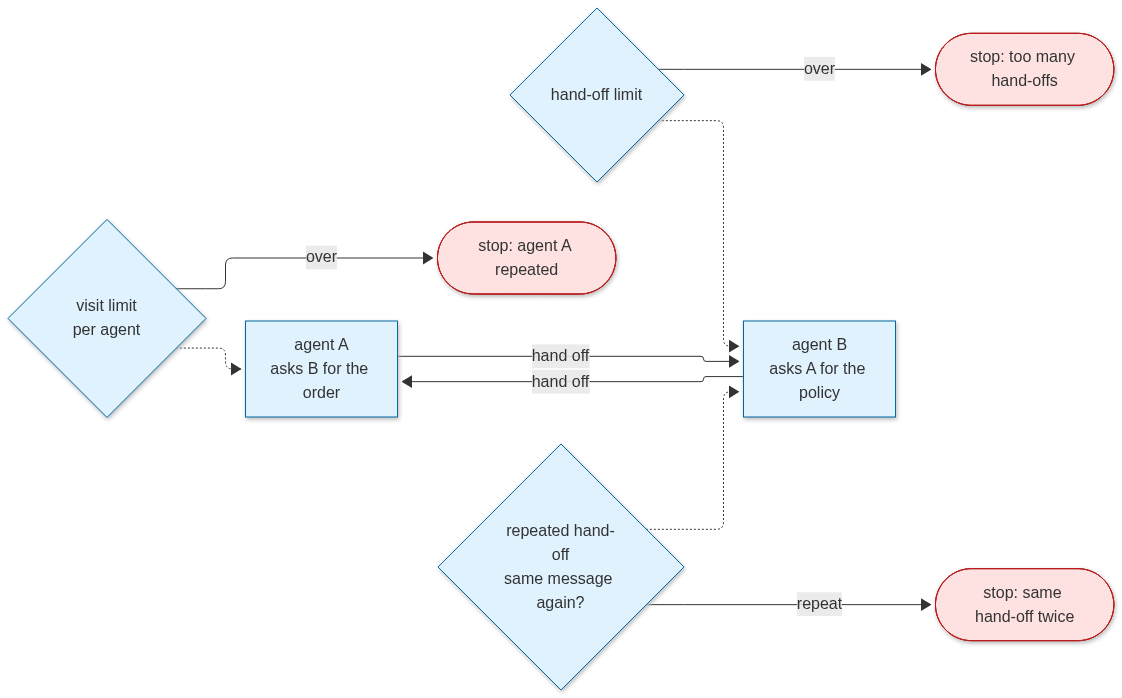

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  A["agent A<br/>asks B for the order"] -->|hand off| B["agent B<br/>asks A for the policy"]
  B -->|hand off| A
  G1{"visit limit<br/>per agent"} -.-> A
  G2{"repeated hand-off<br/>same message again?"} -.-> B
  G3{"hand-off limit"} -.-> B
  G1 -->|over| S1(["stop: agent A repeated"])
  G2 -->|repeat| S2(["stop: same hand-off twice"])
  G3 -->|over| S3(["stop: too many hand-offs"])
  classDef code fill:#e0f2fe,stroke:#0369a1
  classDef stop fill:#fee2e2,stroke:#b91c1c
  class A,B,G1,G2,G3 code
  class S1,S2,S3 stop
""")

## Step by step
Four steps, none of them calls a model. The first two build the failure and the guards; the last two check the lost-context case and compare costs.

**Step 1 · two agents that fail (no call).** Agent A needs the policy and asks B. Agent B needs the order number and asks A. Neither can finish, so
the work goes back and forth. `CALLS` is a counter that stands in for the model bill: each agent turn adds one. `Command` is LangGraph's return
value for a turn: where to go next (`goto`) and what to change in the shared state (`update`).

In [2]:
from typing import Annotated
import operator
from typing_extensions import TypedDict
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command

CALLS = {"n": 0}  # stands in for the model bill: one count per agent turn


class LoopState(TypedDict):
    question: str
    facts: Annotated[list, operator.add]
    visits: dict  # how many turns each agent has taken
    hops: int  # hand-offs so far
    stop: str  # why the run stopped; empty while it runs
    shared: str  # the state the agents pass on; a hand-off must not drop what it holds
    last_msg: str  # the hand-off sent last turn, for the repeat check

Each agent is one node. Its turn adds a line to the shared state and hands off to the other agent.

In [3]:
def agent_a(state: LoopState) -> Command:
    CALLS["n"] += 1
    return Command(goto="agent_b", update={"hops": state["hops"] + 1,
                                           "shared": state["shared"] + " | A asks B for the order"})


def agent_b(state: LoopState) -> Command:
    CALLS["n"] += 1
    return Command(goto="agent_a", update={"hops": state["hops"] + 1,
                                           "shared": state["shared"] + " | B asks A for the policy"})


def build():
    g = StateGraph(LoopState)
    g.add_node("agent_a", agent_a)
    g.add_node("agent_b", agent_b)
    g.add_edge(START, "agent_a")
    return g.compile()

Run it with a recursion limit of 12, which is the runtime's own cap on steps (`config` sets it). When the cap is hit, the runtime raises an
error; the cell catches it and prints the error's name and first line.

In [4]:
CALLS["n"] = 0
try:
    build().invoke({"question": "Order 1003 is lost. What is the refund policy?", "facts": [], "visits": {},
                    "hops": 0, "stop": "", "shared": "start", "last_msg": ""}, config={"recursion_limit": 12})
except Exception as error:  # the runtime's own limit is the only stop; print the name and first line only
    print("no guard: the run stopped by the runtime's limit:", type(error).__name__, "·", str(error).splitlines()[0])
unguarded_calls = CALLS["n"]
print("model-style calls before the stop:", unguarded_calls, "· a run of this shape bills every turn")

no guard: the run stopped by the runtime's limit: GraphRecursionError · Recursion limit of 12 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
model-style calls before the stop: 12 · a run of this shape bills every turn


**Step 2 · the three guards (no call).** Each guard is a check the agent runs before it acts. `guard` runs three checks in order: the **visit
limit** (the agent would run more than `MAX_VISITS` times), the **hand-off limit** (more than `MAX_HOPS` hand-offs in total), and the **repeated
hand-off** check (this hand-off is the same as the one sent last turn, so it adds nothing new to the shared state). A guard returns a reason
string; `None` means the turn may go ahead.

In [5]:
MAX_VISITS = 3
MAX_HOPS = 6


def guard(state: LoopState, agent: str, msg: str) -> str | None:
    visits = state["visits"].get(agent, 0) + 1  # this turn's visit
    if visits > MAX_VISITS:
        return f"visit limit: {agent} ran {visits} times"
    if state["hops"] >= MAX_HOPS:
        return f"hand-off limit: {state['hops']} hand-offs"
    if msg == state["last_msg"]:
        return f"repeated hand-off: '{msg}' was sent last turn"
    return None

`guarded` wraps an agent turn: it runs `guard` first and stops the run with the reason if one fires. Otherwise it does the turn and records the
hand-off in the state.

In [6]:
def guarded(agent: str, other: str):
    def run(state: LoopState) -> Command:
        msg = f"{agent} asks {other}"
        reason = guard(state, agent, msg)
        if reason:
            return Command(goto=END, update={"stop": reason})
        CALLS["n"] += 1
        return Command(goto=other, update={
            "hops": state["hops"] + 1,
            "visits": {**state["visits"], agent: state["visits"].get(agent, 0) + 1},
            "shared": state["shared"] + f" | {msg}",
            "last_msg": msg})
    return run


def build_guarded():
    g = StateGraph(LoopState)
    g.add_node("agent_a", guarded("agent_a", "agent_b"))
    g.add_node("agent_b", guarded("agent_b", "agent_a"))
    g.add_edge(START, "agent_a")
    return g.compile()

Now run the same two agents with the guards on. The recursion limit is raised to 30, so the guards, not the runtime, have to stop the run.

In [7]:
CALLS["n"] = 0
result = build_guarded().invoke({"question": "Order 1003 is lost. What is the refund policy?", "facts": [], "visits": {},
                                 "hops": 0, "stop": "", "shared": "start", "last_msg": ""},
                                config={"recursion_limit": 30})
guarded_calls = CALLS["n"]
print("guarded: stopped because", result["stop"], "· calls:", guarded_calls, "· hand-offs:", result["hops"])

guarded: stopped because visit limit: agent_a ran 4 times · calls: 6 · hand-offs: 6


The ping-pong run above only reaches the visit limit. To see the reason each guard gives, call `guard` on four hand-made states. No run happens here.

In [8]:
base = {"visits": {}, "hops": 0, "last_msg": ""}
cases = [
    ("visit limit", {**base, "visits": {"agent_a": 3}}, "agent_a asks agent_b"),
    ("hand-off limit", {**base, "hops": 6}, "agent_a asks agent_b"),
    ("repeated hand-off", {**base, "last_msg": "agent_a asks agent_b"}, "agent_a asks agent_b"),
    ("no guard fires", base, "agent_a asks agent_b"),
]
for name, state, msg in cases:
    print(f"{name:<18} ->", guard(state, "agent_a", msg))

visit limit        -> visit limit: agent_a ran 4 times
hand-off limit     -> hand-off limit: 6 hand-offs
repeated hand-off  -> repeated hand-off: 'agent_a asks agent_b' was sent last turn
no guard fires     -> None


**Step 3 · lost context (no call).** A hand-off that drops a field is the other failure. `check_handoff` compares the fields a hand-off must keep
(`MUST_KEEP`) with the fields it sends, and returns the names of the missing ones. An empty list means the hand-off is safe. A non-empty list
means it should be refused, so the next agent is never asked to find the field again.

In [9]:
MUST_KEEP = ("order_id", "question")


def check_handoff(sent: dict) -> list[str]:
    return [f"dropped {field}" for field in MUST_KEEP if not sent.get(field)]


print("good hand-off:", check_handoff({"order_id": "1003", "question": "lost parcel policy"}))
print("bad hand-off: ", check_handoff({"question": "lost parcel policy"}))

good hand-off: []
bad hand-off:  ['dropped order_id']


**Step 4 · what the guards cost (no call).** Compare the two runs from Step 1 and Step 2. Each turn is one call, so the call counts are the cost.
The unguarded run was cut off by the runtime's recursion limit; the guarded run stopped on its own.

In [10]:
print(f"unguarded: {unguarded_calls} calls, stopped only by the runtime's recursion limit")
print(f"guarded:   {guarded_calls} calls, stopped by a guard after {result['hops']} hand-offs")
print(f"the guards saved {unguarded_calls - guarded_calls} calls in this run")

unguarded: 12 calls, stopped only by the runtime's recursion limit
guarded:   6 calls, stopped by a guard after 6 hand-offs
the guards saved 6 calls in this run


## At work
- Teams log every guard that stops a run, with its reason. A guard that never fires is either unused or hiding a loop → lesson 25 (observability).
- A stop is a reply. The customer is told a person will follow up, and the run is saved for review → lesson 13 (approval gate).
- The loop costs money on every turn. Count the turns, and cap them, before the first call → lesson 36 (cost and latency).

## What just happened
- The unguarded run made **12** calls and ended with a recursion error, so no answer came back.
- The guarded run made **6** calls and stopped on `visit limit: agent_a ran 4 times`, with 6 hand-offs.
- The four hand-made states gave one reason each for the first three guards, and `None` when no guard fires.
- The field check flagged the hand-off without `order_id` (`dropped order_id`) and passed the good one (`[]`).

## Common mistakes
1. **Relying on the runtime's limit alone.** It stops the run, but with an error and no reply. The cell below shows the error a caller would get
   with a limit of 4. Add guards that give a reason.

In [11]:
try:
    build().invoke({"question": "Order 1003 is lost.", "facts": [], "visits": {}, "hops": 0, "stop": "",
                    "shared": "start", "last_msg": ""}, config={"recursion_limit": 4})
except Exception as error:
    print("caller gets:", type(error).__name__, "·", str(error).splitlines()[0][:60])

caller gets: GraphRecursionError · Recursion limit of 4 reached without hitting a stop conditio


2. **A visit limit that is too high.** Three visits is a fair default; a limit of 100 is no limit.

3. **A repeat check that compares the wrong thing.** Comparing only the sender's name stops normal work: agent A can ask a second, new question
   later. Compare the hand-off's text, as the repeated hand-off check does.

## Production checklist
- Every guard returns a reason, and the reason is stored in the run's state (the `stop` field here) so it can be logged.
- Limits are set per agent and per run, and reviewed when a new specialist is added.
- A test runs the ping-pong case and asserts that the run stops (Step 2 is that test in miniature).
- Each hand-off is checked for its required fields before the next agent starts (Step 3).
- Alert on the rate of guard stops, not only on errors: a rising rate means a loop is forming.

## Try it
Write `repeats(history)` that returns `True` when the last two entries of `history` are equal, and `False` otherwise. Test it on `["a", "b", "b"]` and on
`["a", "b", "c"]`. No model call is needed.

In [12]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [13]:
def repeats(history: list) -> bool:
    return len(history) >= 2 and history[-1] == history[-2]


print(repeats(["a", "b", "b"]), repeats(["a", "b", "c"]))  # True False

True False


## Key terms
- **Ping-pong loop** — two agents hand the same work back and forth without finishing.
- **Visit limit** — a cap on how many turns one agent may take in one run.
- **Hand-off limit** — a cap on the total number of hand-offs in one run.
- **Repeated hand-off check** — refuses a hand-off that is the same as the one sent last turn.
- **Lost context** — a hand-off that drops a field the next agent needs.
- **Recursion limit** — the runtime's own cap on steps; reaching it raises an error.
- **Command** — LangGraph's return value for a turn: where to go next (`goto`) and what to update (`update`).

## Recap
- Two agents that hand work back and forth loop, and the runtime limit is the only stop without a guard.
- A visit limit, a hand-off limit and a repeated hand-off check each stop the run with a reason.
- A hand-off is checked for the fields it must keep, so context is not lost between agents.

**Interview:** "Two of your agents keep handing a customer back and forth. What do you add?" Strong answer: "A per-agent visit limit and a hand-off
limit, both checked before each turn, and a check that a hand-off is not a repeat of the last one. Each stop returns a reason and a reply, and the
run is logged."